## Simple MultiAI Agent Architecture

In [1]:
import os
from typing import TypedDict, Annotated, List, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_tavily import TavilySearch
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [3]:
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [4]:
## Define the state - It will have all the information which will flow through the graph
class AgentState(MessagesState):
    next_agent:str # Which agent should go next

In [5]:
## We will create tools for the Researcher and Writer Agents

@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    # Using Tavily for web search
    search = TavilySearch(max_results=3)
    results = search.invoke(query)
    return str(results)

@tool
def write_summary(content: str) -> str:
    """Write a summary of the provided content."""
    # Simple summary generation
    summary = f"Summary of the findings:\n\n{content[:500]}..."
    return summary

In [6]:
from langchain.chat_models import init_chat_model

llm = init_chat_model("groq:openai/gpt-oss-120b")
llm

ChatGroq(output_version=None, profile={'max_input_tokens': 131072, 'max_output_tokens': 32768, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True}, client=<groq.resources.chat.completions.Completions object at 0x000001EF6DFD0CB0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001EF6DD93560>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None)

In [7]:
# In our simple multi agent systen, the researcher agent will be utilizing the LLM, and also the Tavily web search as a tool.
## Then the response will be given to the Writer agent, it will utilise the LLM and also the summary tool

In [8]:
# Define agent functions (simpler approach)

# Create autonomous Researcher ReAct agent
researcher_react_agent = create_react_agent(
    llm,
    tools=[search_web],
    prompt="You are a research assistant. Use the search_web tool to find information about the user's request. Synthesize your findings clearly."
)

def researcher_agent(state: AgentState):
    """Researcher agent that searches for information"""
    # The ReAct agent executes the search tool and synthesizes the findings
    result = researcher_react_agent.invoke({"messages":state["messages"]})

    # Extract the final synthesized message from the researcher
    final_message = result["messages"][-1]

    # Return the response and route to writer
    return {
        "messages":[final_message],
        "next_agent":"writer"
    }


C:\Users\Mohammad Ausaf Shah\AppData\Local\Temp\ipykernel_11544\7934720.py:4: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  researcher_react_agent = create_react_agent(


In [9]:
def writer_agent(state:AgentState):
    """Writer agent that creates summaries"""

    messages = state["messages"]

    # Add system message
    system_msg = SystemMessage(content="You are a technical writer. Review the conversation and create a clear, concise summary of the findings.")

    # Simple completion without tools
    response = llm.invoke([system_msg] + messages)

    return {
        "messages":[response],
        "next_agent":"end"
    }

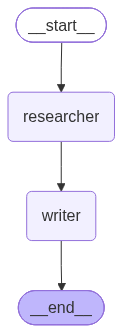

In [10]:
# Build graph

workflow = StateGraph(MessagesState)

# Add nodes
workflow.add_node("researcher", researcher_agent)
workflow.add_node("writer",writer_agent)

# Define workflow

workflow.set_entry_point("researcher")
workflow.add_edge("researcher","writer")
workflow.add_edge("writer",END)

final_workflow = workflow.compile()

final_workflow

In [11]:
response = final_workflow.invoke({"messages":"Reasearch about the usecase of agentic ai in telecom"})
response

{'messages': [HumanMessage(content='Reasearch about the usecase of agentic ai in telecom', additional_kwargs={}, response_metadata={}, id='e710a3bb-0c5c-4fbb-9596-137f60c7d700'),
  AIMessage(content='**Agentic AI in Telecommunications – A Research Synopsis (July\u202f2024)**  \n\n---\n\n## 1. What “Agentic AI” Means for Telcos  \n\n*Agentic AI* refers to autonomous, goal‑oriented software agents that can **perceive** (ingest telemetry, customer data, etc.), **reason** (interpret intent, run inference), and **act** (execute configuration changes, launch services, or interact with users) without continuous human supervision. In telecom, these agents are layered on top of existing OSS/BSS, network‑function‑virtualisation (NFV) and edge‑cloud stacks, turning data‑rich environments into self‑governing ecosystems.  \n\n> **Key properties** (GSMA) – intent understanding, autonomous decision‑making, and execution of complex tasks across network, operations and customer‑facing domains【2†content

In [12]:
response["messages"][-1].content

'**Summary of Findings – Agentic AI in Telecommunications**\n\n---\n\n### 1. What is Agentic AI?\n- Autonomous, goal‑oriented software agents that **perceive** data, **reason** about intent, and **act** (configure, remediate, interact) without continuous human supervision.\n- Built on top of OSS/BSS, NFV, and edge‑cloud stacks to create self‑governing network ecosystems.\n\n---\n\n### 2. Core Use‑Case Categories & Benefits\n| Category | Agent Functions | Key Business/Technical Gains |\n|----------|----------------|------------------------------|\n| **Self‑Healing / Self‑Optimising Networks** | Detect anomalies, reroute traffic, auto‑scale VNFs | ↑ Availability, ↓ MTTR (seconds vs hours), lower OPEX |\n| **Predictive Maintenance** | Analyse sensor data, forecast failures, schedule repairs | ↓ Downtime 30‑40\u202f%, extended asset life, efficient crew routing |\n| **Dynamic Service Orchestration / Edge Computing** | Auto‑orchestrate VNFs, slice resources based on demand | Faster service 

In [13]:
## This is a multi agent system as two agentic nodes work one after another

## Supervisor Multi-AI Agent Architecture

In [14]:
from typing import TypedDict, Annotated, List, Literal, Dict, Any
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver
import random
from datetime import datetime

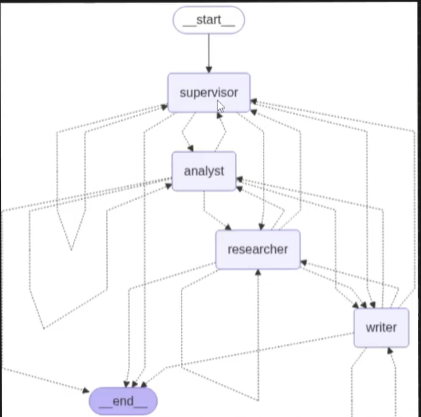

We are going to build the above multi-agent architecture. Here, once we give the input, the supervisor will decide whether to send the analyst or the researcher or the writer.

In [15]:
# ===================================
# State Definition
# ===================================

# Below commented code is just for my understanding that we can do this as well

# class SupervisorState(MessagesState):
#     """State for the multi-agent system"""
#     current_agent: str = ""
#     task_assignments: Dict[str,List[str]] = {} # Track what each agent should do
#     agent_outputs: Dict[str, Any] = {} # Store outputs from each agent
#     workflow_stage: str = "initial" # Track workflow progress
#     iteration_count: int = 0
#     max_iterations: int = 10
#     final_output: str = ""


# ===================================
# State Definition
# ===================================

class SupervisorState(MessagesState):
    """State for the multi-agent system"""
    next_agent: str = ""
    research_data: str = ""
    analysis: str = ""
    final_report: str = ""
    task_complete: bool = False
    current_task: str = ""

In [16]:
# ===================================
# Supervisor with Groq LLM
# ===================================
from langchain_core.prompts import ChatPromptTemplate

def create_supervisor_chain():
    """Creates the supervisor decision chain"""

    supervisor_prompt = ChatPromptTemplate.from_messages([
        (
            "system","""You are a supervisor managing a team of agents:
        
            1. Researcher - Gathers information and data
            2. Analyst - Analyzes data and provides insights  
            3. Writer - Creates reports and summaries

            Based on the current state and conversation, decide which agent should work next.
            If the task is complete, respond with 'DONE'.

            Current state:
            - Has research data: {has_research}
            - Has analysis: {has_analysis}
            - Has report: {has_report}

            Respond with ONLY the agent name (researcher/analyst/writer) or 'DONE'."""
        ),
        ("human","{task}")
    ])

    return supervisor_prompt | llm # The LCEL Pipe Operator. (|) is overloaded to chain components together

In [17]:
def supervisor_agent(state: SupervisorState) -> Dict:
    """Supervisor decides next agent using Groq LLM"""

    messages = state["messages"]
    task = messages[-1].content if messages else "No task"

    # Check what's been completed
    has_research = bool(state.get("research_data",""))
    has_analysis = bool(state.get("analysis",""))
    has_report = bool(state.get("final_report",""))

    # Get LLM decision
    chain = create_supervisor_chain()
    decision = chain.invoke({
        "task": task,
        "has_research": has_research,
        "has_analysis": has_analysis,
        "has_report": has_report
    })

    # Parse decision
    decision_text = decision.content.strip().lower()
    print(decision_text)

    # Determine next agent
    if has_report and decision_text == "done":
        next_agent = "end"
        supervisor_msg = "Supervisor: All tasks complete! Great work team."
    elif "researcher" in decision_text or not has_research:
        next_agent = "researcher"
        supervisor_msg = "Supervisor: Let's start with research. Assigning to Researcher..."
    elif "analyst" in decision_text or (has_research and not has_analysis):
        next_agent = "analyst"
        supervisor_msg = "Supervisor: Research done. Time for analysis. Assigning to Analyst..."
    elif "writer" in decision_text or (has_analysis and not has_report):
        next_agent = "writer"
        supervisor_msg = "Supervisor: Analysis complete. Let's create the report. Assigning to Writer..."
    else:
        next_agent = "end"
        supervisor_msg = "Supervisor: Task seems complete."
    
    return {
        "messages": [AIMessage(content=supervisor_msg)],
        "next_agent": next_agent,
        "current_task": task
    }

In [18]:
# ===================================
# Agent 1: Researcher (using Groq)
# ===================================

def researcher_agent(state: SupervisorState) -> Dict:
    """Researcher uses Groq to gather information"""

    task = state.get("current_task","research topic") # If in the state we dont find the value for "current_task", it returns "research topic" instead of an error

    # Create research prompt
    research_prompt = f"""As a research specialist, provide comprehensive information about: {task}

    Include:
    1. Key facts and background
    2. Current trends or developments
    3. Important statistics or data points
    4. Notable examples or case studies
    
    Be concise but thorough."""

    # Get research from LLM
    research_response = llm.invoke([HumanMessage(content=research_prompt)])
    research_data = research_response.content

    # Create agent message
    agent_message = f"🔍 Researcher: I've completed the research on '{task}'.\n\nKey findings:\n{research_data[:500]}..."

    return {
        "messages": [AIMessage(content=agent_message)],
        "research_data": research_data,
        "next_agent": "supervisor"
    }

In [19]:
# ===================================
# Agent 2: Analyst (using Groq)
# ===================================

def analyst_agent(state: SupervisorState) -> Dict:
    """Analyst uses Groq to analyze the research"""

    research_data = state.get("research_data","")
    task = state.get("current_task","")

    # Create analysis prompt
    analysis_prompt = f"""As a data analyst, analyze this research data and provide insights:

    Research Data:
    {research_data}

    Provide:
    1. Key insights and patterns
    2. Strategic implications
    3. Risks and opportunities
    4. Recommendations

    Focus on actionable insights related to: {task}"""

    # Get analysis from LLM
    analysis_response = llm.invoke([HumanMessage(content=analysis_prompt)])
    analysis = analysis_response.content

    # Create agent message
    agent_message = f"📊 Analyst: I've completed the analysis.\n\nTop insights:\n{analysis[:400]}..."

    return {
        "messages": [AIMessage(content=agent_message)],
        "analysis": analysis,
        "next_agent": "supervisor"
    }


In [20]:
# ===================================
# Agent 3: Writer (using Groq)
# ===================================

def writer_agent(state: SupervisorState) -> Dict:
    """Writer uses Groq to create final report"""

    research_data = state.get("research_data","")
    analysis = state.get("analysis","")
    task = state.get("current_task","")

    # Create writing prompt
    writing_prompt = f"""As a professional writer, create an executive report based on:

    Task: {task}

    Research Findings:
    {research_data[:1000]}

    Analysis:
    {analysis[:1000]}

    Create a well-structured report with:
    1. Executive Summary
    2. Key Findings  
    3. Analysis & Insights
    4. Recommendations
    5. Conclusion

    Keep it professional and concise."""

    # Get report from LLM
    report_response = llm.invoke([HumanMessage(content = writing_prompt)])
    report = report_response.content

    # Create final formatted report
    final_report = f"""
    📄 FINAL REPORT
    {'='*50}
    Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}
    Topic: {task}
    {'='*50}

    {report}

    {'='*50}
    Report compiled by Multi-Agent AI System powered by Groq
    """

    return{
        "messages": [AIMessage(content=f"✍️ Writer: Report complete! See below for the full document.")],
        "final_report": final_report,
        "next_agent": "supervisor",
        "task_complete": True
    }

In [21]:
# ===================================
# Router Function
# ===================================

def router(state: SupervisorState) -> Literal["supervisor", "analyst", "writer", "__end__"]:
    """Routes to next agent based on state"""

    next_agent = state.get("next_agent","supervisor")

    if next_agent == "end" or state.get("task_complete", False):
        return END
    
    if next_agent in ["supervisor", "researcher", "analyst", "writer"]:
        return next_agent
    
    return "supervisor"

In [22]:
# Create workflow
workflow = StateGraph(SupervisorState)

# Add nodes
workflow.add_node("supervisor", supervisor_agent)
workflow.add_node("researcher", researcher_agent)
workflow.add_node("analyst", analyst_agent)
workflow.add_node("writer", writer_agent)

# Set entry point
workflow.set_entry_point("supervisor")

# Add routing
for node in ["supervisor", "researcher", "analyst", "writer"]: # We run a loop so that we map every node to every node
    workflow.add_conditional_edges(
        node, # 1. Where execution is coming FROM
        router, # 2. Function that inspects State and makes a decision (connecting node to itself and others here)
        { # 3. Dictionary mapping decisions to destination nodes, Lookup Table (Mapping). Meaning if If router() returns "researcher", LangGraph looks up "researcher" on the left → goes to "researcher" on the right.
            "supervisor": "supervisor",
            "researcher": "researcher",
            "analyst": "analyst",
            "writer": "writer",
            END: END
        }
    )
graph = workflow.compile()

# Why pass the full dictionary inside the loop every time?
# Ans: add_conditional_edges configures one source node at a time.
#      Whenever execution leaves that node, LangGraph asks:
#      "From this node, if router() returns value X, which node should I jump to?"

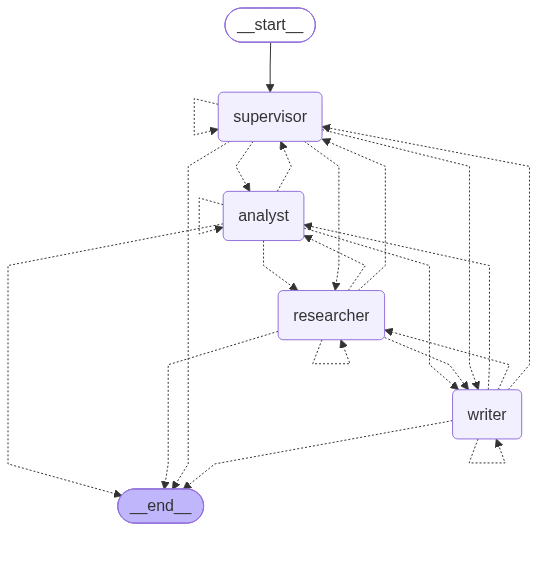

In [23]:
graph

In [28]:
response = graph.invoke({
    "messages": [HumanMessage(content="What are the benefits and risks of AI in healthcare?")]
})

researcher
analyst
writer


In [29]:
print("Keys in response:", response.keys())
for msg in response.get("messages", []):
    print(msg.content)

Keys in response: dict_keys(['messages', 'next_agent', 'research_data', 'analysis', 'final_report', 'task_complete', 'current_task'])
What are the benefits and risks of AI in healthcare?
Supervisor: Let's start with research. Assigning to Researcher...
🔍 Researcher: I've completed the research on 'What are the benefits and risks of AI in healthcare?'.

Key findings:
**AI in Healthcare – Benefits, Risks, and the Current Landscape**  
*(Compiled for a research‑oriented audience; sources are indicated where possible.)*

---

## 1. Key Facts & Background  

| Aspect | Detail |
|--------|--------|
| **Definition** | Use of machine‑learning (ML), deep learning, natural‑language processing (NLP), and other AI techniques to augment or automate clinical, operational, and research activities. |
| **Historical Milestones** | • 1970s‑80s: Early expert systems (e.g., MY...
Supervisor: Research done. Time for analysis. Assigning to Analyst...
📊 Analyst: I've completed the analysis.

Top insights:
Be

In [30]:
print(response.get("messages"))

[HumanMessage(content='What are the benefits and risks of AI in healthcare?', additional_kwargs={}, response_metadata={}, id='2465bb62-9cce-4b94-aced-d3fb01d22317'), AIMessage(content="Supervisor: Let's start with research. Assigning to Researcher...", additional_kwargs={}, response_metadata={}, id='9c215716-8b9f-46ca-b1aa-a5c4ea3c446d', tool_calls=[], invalid_tool_calls=[]), AIMessage(content="🔍 Researcher: I've completed the research on 'What are the benefits and risks of AI in healthcare?'.\n\nKey findings:\n**AI in Healthcare – Benefits, Risks, and the Current Landscape**  \n*(Compiled for a research‑oriented audience; sources are indicated where possible.)*\n\n---\n\n## 1. Key Facts & Background  \n\n| Aspect | Detail |\n|--------|--------|\n| **Definition** | Use of machine‑learning (ML), deep learning, natural‑language processing (NLP), and other AI techniques to augment or automate clinical, operational, and research activities. |\n| **Historical Milestones** | • 1970s‑80s: Ear

In [33]:
response['final_report']

"\n    📄 FINAL REPORT\n    ==================================================\n    Generated: 2026-11-17 21:06\n    Topic: 📊 Analyst: I've completed the analysis.\n\nTop insights:\nBelow is a **research‑oriented synthesis** that pulls the most salient patterns from the data you compiled, translates them into strategic take‑aways, highlights the most consequential risks\u202f/\u202fopportunities, and ends with concrete next‑steps you can act on right away.\n\n---\n\n## 1️⃣ Key Insights & Patterns  \n\n| Theme | What the data repeatedly shows | Why it matters |\n|-------|----------------------...\n    ==================================================\n\n    **Executive Report – AI in Healthcare**  \n*Prepared for senior leadership, research‑oriented audience*  \n\n---\n\n## 1. Executive Summary  \n\nArtificial‑intelligence (AI) technologies—machine‑learning, deep‑learning, natural‑language processing, and multimodal models—have moved from experimental prototypes to clinically‑parity too

In [35]:
from IPython.display import display, Markdown
# If you want the Writer's final report:
if response.get("final_report"):
    display(Markdown(response["final_report"]))
else:
    # Fallback to the last message in the thread:
    display(Markdown(response["messages"][-1].content))


    📄 FINAL REPORT
    ==================================================
    Generated: 2026-11-17 21:06
    Topic: 📊 Analyst: I've completed the analysis.

Top insights:
Below is a **research‑oriented synthesis** that pulls the most salient patterns from the data you compiled, translates them into strategic take‑aways, highlights the most consequential risks / opportunities, and ends with concrete next‑steps you can act on right away.

---

## 1️⃣ Key Insights & Patterns  

| Theme | What the data repeatedly shows | Why it matters |
|-------|----------------------...
    ==================================================

    **Executive Report – AI in Healthcare**  
*Prepared for senior leadership, research‑oriented audience*  

---

## 1. Executive Summary  

Artificial‑intelligence (AI) technologies—machine‑learning, deep‑learning, natural‑language processing, and multimodal models—have moved from experimental prototypes to clinically‑parity tools across diagnosis, care delivery, and research. The market is expanding rapidly (≈ US $188 bn by 2030, 38 % CAGR) and early adopters are already reporting measurable cost‑savings (≈ US $1.2 bn/yr in radiology).  

Key take‑aways:  

| Insight | Strategic Implication |
|---------|----------------------|
| **Performance parity** – AI models achieve ≥ 90 % AUC on major imaging tasks; LLMs draft notes at clinician‑level quality. | Enables wider deployment, justifies investment, and accelerates workflow automation. |
| **Regulatory momentum** – FDA’s SaMD framework and 2022 AI/ML‑SaMD guidance, EU MDR 2021, and emerging global standards. | Provides clearer pathways for market entry but adds compliance overhead. |
| **Economic upside** – Forecasted $188 bn market, significant operational savings, and new revenue streams (AI‑enabled services). | Strong ROI potential; prioritise high‑impact use‑cases (radiology, pathology, triage). |
| **Risk landscape** – Data bias, model drift, cybersecurity, and liability concerns. | Necessitates robust governance, continuous monitoring, and stakeholder education. |

The report below expands on these findings, analyses the underlying patterns, and outlines actionable recommendations.

---

## 2. Key Findings  

| Aspect | Detail |
|--------|--------|
| **Definition** | AI in healthcare leverages ML, deep learning, NLP, and multimodal AI to augment or automate clinical, operational, and research activities. |
| **Historical Milestones** | • 1970s‑80s – Expert systems (e.g., MYCIN). <br>• 1990s‑2000s – Early image‑analysis algorithms for radiology. <br>• 2010s – Deep‑learning breakthroughs (CNNs for pathology slides). <br>• 2020‑present – Large language models (LLMs) and multimodal AI (image + text). |
| **Regulatory Context** | • FDA “Software as a Medical Device” (SaMD) framework. <br>• EU Medical Device Regulation (MDR) 2021. <br>• FDA 2022 “Proposed Regulatory Framework for AI/ML‑Based SaMD”. |
| **Economic Impact** | • Global AI‑in‑healthcare market projected at **US $188 bn by 2030** (CAGR ≈ 38 %). <br>• US radiology alone saving **≈ US $1.2 bn per year** through AI‑assisted workflow. |
| **Performance Benchmarks** | • Imaging: ≥ 90 % AUC on chest‑X, CT, mammography. <br>• Clinical documentation: LLMs (GPT‑4, Claude) produce draft notes with clinician‑level fluency and suggest differential diagnoses. |
| **Adoption Hotspots** | Radiology, pathology, dermatology, clinical decision support, patient triage, and administrative automation (e.g., coding, billing). |
| **Principal Risks** | • Data bias & representativeness. <br>• Model drift & post‑deployment performance decay. <br>• Cybersecurity & data‑privacy exposures. <br>• Liability & malpractice uncertainty. |
| **Key Opportunities** | • Value‑based care incentives for outcome‑driven AI. <br>• Integration of AI with telehealth & remote monitoring. <br>• Partnerships with AI‑native startups for rapid capability acquisition. |

---

## 3. Analysis & Insights  

### 3.1 Performance Gains → Adoption Threshold  
Deep‑learning models now consistently meet or exceed human expert performance on core imaging tasks, while LLMs have demonstrated utility in note‑taking and decision‑support. This **clinical parity** removes the “proof‑of‑concept” barrier and shifts focus to integration, workflow redesign, and change‑management.

### 3.2 Regulatory Evolution → Market Clarity & Compliance Cost  
The FDA’s 2022 AI/ML SaMD guidance introduces a **total product lifecycle (TPLC)** approach, mandating pre‑market submission, post‑market monitoring, and change‑control plans. While this clarifies pathways, it also raises compliance costs (quality‑system documentation, real‑world performance tracking). Organizations that embed TPLC early gain a competitive advantage.

### 3.3 Economic Drivers → Prioritisation Matrix  
High‑volume, high‑margin specialties (radiology, pathology) deliver the quickest ROI because:  
* Large data volumes enable robust model training.  
* Repetitive, image‑heavy workflows are amenable to automation.  
* Reimbursement models increasingly reward efficiency and outcome improvements.

### 3.4 Risk‑Opportunity Trade‑off  
*Bias & data quality* are the most cited barriers; however, systematic bias mitigation (diverse training sets, fairness audits) can become a **differentiator** for trust‑centric markets.  
*Cybersecurity* risk is mitigated by adopting zero‑trust architectures and continuous vulnerability scanning of AI pipelines.  
*Liability* concerns can be addressed through clear human‑in‑the‑loop policies and updated malpractice coverage.

### 3.5 Competitive Landscape  
Major tech firms (Google Health, Microsoft, IBM) are partnering with health systems, while a surge of niche startups focuses on specialty AI (e.g., AI‑driven pathology slide analysis). Consolidation is expected as larger players acquire best‑in‑class niche solutions.

---

## 4. Recommendations  

| Recommendation | Rationale | Timeline / Owner |
|----------------|-----------|-------------------|
| **Establish an AI Governance Office** | Centralises policy, compliance, model‑monitoring, and ethics oversight; aligns with FDA TPLC. | Q1‑2025, Chief Digital Officer |
| **Pilot High‑Impact Use‑Cases** (radiology triage, pathology slide classification, LLM‑assisted documentation) | Leverages existing data assets, demonstrates ROI, and builds internal expertise. | 6‑month pilots, Clinical Leads |
| **Implement a Model‑Lifecycle Management Platform** (MLOps) | Enables continuous monitoring, version control, and rapid re‑training to counter model drift. | Q2‑2025, IT & Data Science |
| **Develop a Data‑Bias Audit Framework** | Systematic assessment of training data representativeness; mitigates regulatory and reputational risk. | Q3‑2025, Compliance & Analytics |
| **Negotiate Updated Liability Coverage** | Aligns insurance with AI‑augmented practice; clarifies responsibility in AI‑driven decisions. | Q4‑2025, Legal & Risk Management |
| **Form Strategic Partnerships** with AI‑focused startups or academic labs for co‑development and access to cutting‑edge algorithms. | Accelerates innovation while sharing development risk. | Ongoing, Business Development |
| **Invest in Workforce Upskilling** (AI literacy for clinicians, data‑science training for IT staff). | Ensures adoption, reduces resistance, and maximises tool effectiveness. | Continuous, HR & Learning & Development |

---

## 5. Conclusion  

AI is no longer a speculative technology in healthcare; it is a **value‑creating engine** poised to reshape diagnostics, care delivery, and operational efficiency. The convergence of proven performance, supportive regulatory frameworks, and compelling economic incentives creates a narrow window for decisive action. By institutionalising governance, targeting high‑ROI pilots, and proactively managing risks, the organization can capture market share, improve patient outcomes, and secure a sustainable competitive advantage in the AI‑enabled health ecosystem.  

---  

*Prepared by: Analyst Team*  
*Date: 17 Nov 2026*  

    ==================================================
    Report compiled by Multi-Agent AI System powered by Groq
    